# 09 — Chọn class weighting trên validation

Dùng **Restart Kernel → Run All** với venv `D:\UIT\.venvs\ml-gpu`.
Chạy CPU, mặc định 4 thread. Không cần GPU hay phụ thuộc cũ của Feedzai.

**Mục tiêu:** so sánh `none`, `balanced`, `tuned` với cùng 24 cấu hình model,
cùng ngân sách cây. Tổng 72 fit HPO, tối đa 6 fit bổ sung cho 3 seed.
Mỗi fit tối đa 1.000 cây. Có heartbeat sau mỗi 15 giây trong khi train.

**Split:** train tháng 0–5, validation tháng 6, test tháng 7.
Chọn cấu hình bằng AP validation ở seed42; cố định cấu hình của mỗi phương pháp.
Dùng seed42 đã fit và thêm seed317/2026. Chọn ngưỡng riêng cho mỗi model trên
validation với FPR ≤5%, cố định cả 9 ngưỡng trước khi đánh giá test.

Tháng 7 đã xuất hiện trong các notebook trước. Đây là kiểm tra tiếp có công khai
lịch sử xem test, không phải một holdout hoàn toàn mới. Không dùng trial84 hay
thứ hạng test của notebook08 để chọn cấu hình. Quy trình này khác split của 08.

## 1. Project và cache trên ổ của project

In [1]:
from pathlib import Path
import importlib
import importlib.metadata
import os
import subprocess
import sys

PROJECT_DIR = None
here = Path.cwd().resolve()
ROOT = (
    Path(PROJECT_DIR).resolve()
    if PROJECT_DIR
    else next(
        (p for p in [here, *here.parents] if (p / "data/raw/Base.csv").is_file()),
        None,
    )
)
if ROOT is None:
    raise FileNotFoundError("Mở BAF_project hoặc điền PROJECT_DIR.")

for key, folder in [("PIP_CACHE_DIR", "pip-cache"), ("TEMP", "tmp"), ("TMP", "tmp")]:
    path = ROOT / "external" / "step09_runtime" / folder
    path.mkdir(parents=True, exist_ok=True)
    os.environ[key] = str(path)


### Kiểm tra các thư viện đang dùng

In [2]:
required = {
    "lightgbm": "lightgbm==4.7.0",
    "nbformat": "nbformat==5.11.1",
    "ipython": "ipython==9.17.1",
    "psutil": "psutil==7.2.2",
    "matplotlib": "matplotlib>=3.8",
}
missing = []
for name, requirement in required.items():
    try:
        importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        missing.append(requirement)
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)


In [3]:
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import Image, display
import baf

baf = importlib.reload(baf)
baf.require(
    Path(baf.__file__).resolve() == (ROOT / "src/baf.py").resolve(),
    "Kernel đã import source từ project khác.",
)
expected_source_hash = (
    "c6d70e56c4c8fe0aaac2bb2cb5cb75cb" "1fdd9be6b21baae2326a077026e7cebe"
)
baf.require(
    baf.sha256(ROOT / "src/baf.py") == expected_source_hash,
    "Source khác gói bước09; giải nén đúng gói và Restart Kernel.",
)
print("Python:", sys.executable)
print("Packages:", baf.package_versions())


Python: d:\UIT\.venvs\ml-gpu\Scripts\python.exe
Packages: {'numpy': '2.5.4', 'pandas': '3.1.0', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'psutil': '7.2.2', 'lightgbm': '4.7.0'}


## 2. Cấu hình và ngân sách cố định

In [4]:
DATA_PATH = ROOT / "data/raw/Base.csv"

CONFIG = baf.WeightingConfig(
    candidates=24,
    plan_seed=9026,
    search_seed=42,
    seeds=(42, 317, 2026),
    threads=4,
    max_trees=1000,
    max_fpr=0.05,
    powers=(0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5),
    heartbeat_seconds=15.0,
)
CONFIG.validate()
print(CONFIG)


WeightingConfig(candidates=24, plan_seed=9026, search_seed=42, seeds=(42, 317, 2026), threads=4, max_trees=1000, max_fpr=0.05, powers=(0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5), heartbeat_seconds=15.0, expected_rows=1000000, expected_data_sha256='7bf10a37ce07e72e14c1b09e5efee3d27261baff4facc7da767b0474dcf9b809', dataset_tag='BAF_Base')


`tuned` chọn cả tham số model và độ mạnh trọng số trong đúng 24 lượt;
không chạy 24 × 7 lượt. Mỗi cấu hình model ghép với một power đã được lập trước.
Cả ba phương pháp có cùng số candidate và cùng tổng số cây yêu cầu.

Với `r = n_negative / n_positive` tính **chỉ từ train**:
tỷ lệ `w_positive / w_negative = r ** power`, sau đó chuẩn hóa để mean weight=1.
Power0 khớp `none`; power1 khớp `balanced`. Không cộng thêm `class_weight`,
`scale_pos_weight` hay `is_unbalance` khi đã truyền `sample_weight`.

In [5]:
plan = baf.weighting_candidate_plan(CONFIG)
preview = pd.DataFrame(
    {
        "candidate": row["candidate"] + 1,
        "trees": row["parameters"]["n_estimators"],
        "leaves": row["parameters"]["num_leaves"],
        "learning_rate": row["parameters"]["learning_rate"],
        "tuned_power": row["power"],
    }
    for row in plan
)
display(preview)
print("HPO fits:", len(plan) * 3)
print("Requested HPO trees per method:", int(preview.trees.sum()))
print("Additional evaluation-seed fits:", 3 * (len(CONFIG.seeds) - 1))


,candidate,trees,leaves,learning_rate,tuned_power
0,1,300,31,0.050000,0.25
1,2,1000,15,0.026373,1.25
2,3,1000,31,0.037093,1.25
3,4,1000,15,0.023579,0.75
4,5,1000,15,0.094502,0.25
5,6,600,15,0.086032,0.00
6,7,1000,63,0.036300,1.50
7,8,150,63,0.060029,0.00
8,9,1000,63,0.052232,0.25
9,10,1000,31,0.025841,0.75


HPO fits: 72
Requested HPO trees per method: 14800
Additional evaluation-seed fits: 6


## 3. Run mới hoặc tiếp tục một run bị ngắt

In [6]:
RESUME_RUN = None
# Ví dụ: r"D:\UIT\DS317\BAF_project\results\runs\weighting_study_..."

RUN_DIR = (
    Path(RESUME_RUN).resolve()
    if RESUME_RUN
    else baf.new_directory(ROOT / "results/runs", "weighting_study")
)
print("Run:", RUN_DIR)


Run: D:\UIT\DS317\BAF_project\results\runs\weighting_study_20261028_090757_5132feb0


Mặc định mỗi Run All tạo run mới. Muốn tiếp tục, điền đúng thư mục run ở
`RESUME_RUN`, giữ nguyên CONFIG và source, rồi Restart Kernel → Run All.
Run cũ phải có cùng dữ liệu/hash, versions, source, seed và candidate plan.
Fit đã hoàn tất được kiểm tra và dùng lại; fit đang dở sẽ chạy lại.

## 4. Chạy HPO → cố định model/ngưỡng → đánh giá test

In [7]:
RUN_DIR = baf.launch_weighting_study(
    data_path=DATA_PATH,
    output=RUN_DIR,
    config=CONFIG,
)


BEGIN_STAGE 1
                 n positive              months
train       794989     8151  [0, 1, 2, 3, 4, 5]
validation  108168     1450                 [6]
test         96843     1428                 [7]
END_STAGE 1
BEGIN_STAGE 2
SEARCH_METHOD none candidates= 24
FIT hpo none candidate=1/24 seed=42: requested trees=300
HEARTBEAT hpo none candidate=1/24 seed=42: trees=64/300, elapsed=15s
HEARTBEAT hpo none candidate=1/24 seed=42: trees=152/300, elapsed=30s
HEARTBEAT hpo none candidate=1/24 seed=42: trees=267/300, elapsed=45s
DONE hpo_none_000_42: validation AP=0.181368, fit=48.7s
FIT hpo none candidate=2/24 seed=42: requested trees=1000
HEARTBEAT hpo none candidate=2/24 seed=42: trees=91/1000, elapsed=15s
HEARTBEAT hpo none candidate=2/24 seed=42: trees=196/1000, elapsed=30s
HEARTBEAT hpo none candidate=2/24 seed=42: trees=304/1000, elapsed=45s
HEARTBEAT hpo none candidate=2/24 seed=42: trees=418/1000, elapsed=60s
HEARTBEAT hpo none candidate=2/24 seed=42: trees=550/1000, elapsed=75s


Theo dõi `FIT`, `HEARTBEAT`, `DONE` và `CACHE` trong output.
`ALL_MODELS_AND_THRESHOLDS_FROZEN` phải xuất hiện trước phần test.
Notebook thực thi thật và log của từng lần chạy nằm trong
`evidence/executions`; `study_executed.ipynb` là bản lần chạy gần nhất.

## 5. Kiểm chứng và xuất proof một lượt

In [8]:
archive = baf.export_weighting_proof(
    output=RUN_DIR,
    proof_root=ROOT / "results/proofs",
)
print("Proof:", archive)


Verifying validation/test scores and checkpoints; no fitting.
CLASS_WEIGHT_PROOF_VERIFIED
  method  candidate  power  validation_ap
    none          1   0.00       0.182771
balanced          1   1.00       0.183200
   tuned          0   0.25       0.183933
 partition   method  seeds  ap_mean   ap_std  recall_mean  recall_std  fpr_mean  fpr_std  precision_mean  precision_std
      test balanced      3 0.221808 0.001759     0.533847    0.003594  0.040133 0.000826        0.166049       0.001917
      test     none      3 0.218460 0.000941     0.540149    0.002651  0.038988 0.000333        0.171745       0.001747
      test    tuned      3 0.213992 0.002138     0.541083    0.003454  0.040954 0.000567        0.165097       0.001037
validation balanced      3 0.183101 0.000483     0.531034    0.004195  0.049814 0.000123        0.126520       0.001030
validation     none      3 0.181645 0.000982     0.528736    0.004434  0.049910 0.000141        0.125826       0.000765
validation    tuned   

Export tính lại AP, threshold, metric, số cây và hash từ file đã lưu.
Không train lại và không phụ thuộc Ctrl+S hay tên file notebook đang mở.
ZIP gồm toàn bộ candidate, các model, dự đoán, selection/freeze/seal,
source snapshot, output chạy thật, bảng kết quả, biểu đồ và `verify.ipynb`.

## 6. Đọc kết quả

Selected using validation only:


,method,candidate,power,validation_ap
0,none,1,0.00,0.182771
1,balanced,1,1.00,0.183200
2,tuned,0,0.25,0.183933


Test: mean and sample standard deviation across seeds:


,partition,method,seeds,ap_mean,ap_std,recall_mean,recall_std,fpr_mean,fpr_std,precision_mean,precision_std
0,test,balanced,3,0.221808,0.001759,0.533847,0.003594,0.040133,0.000826,0.166049,0.001917
1,test,none,3,0.218460,0.000941,0.540149,0.002651,0.038988,0.000333,0.171745,0.001747
2,test,tuned,3,0.213992,0.002138,0.541083,0.003454,0.040954,0.000567,0.165097,0.001037


Paired test deltas vs none; recall/FPR deltas use percentage points:


,method,seed,delta_ap,delta_recall_pp,delta_fpr_pp
0,balanced,42,0.002480,0.070028,0.175025
1,balanced,317,0.001286,-1.050420,0.076508
2,balanced,2026,0.006277,-0.910364,0.092229
3,tuned,42,-0.006773,0.560224,0.191794
4,tuned,317,-0.004814,-0.420168,0.168737
5,tuned,2026,-0.001818,0.140056,0.229524


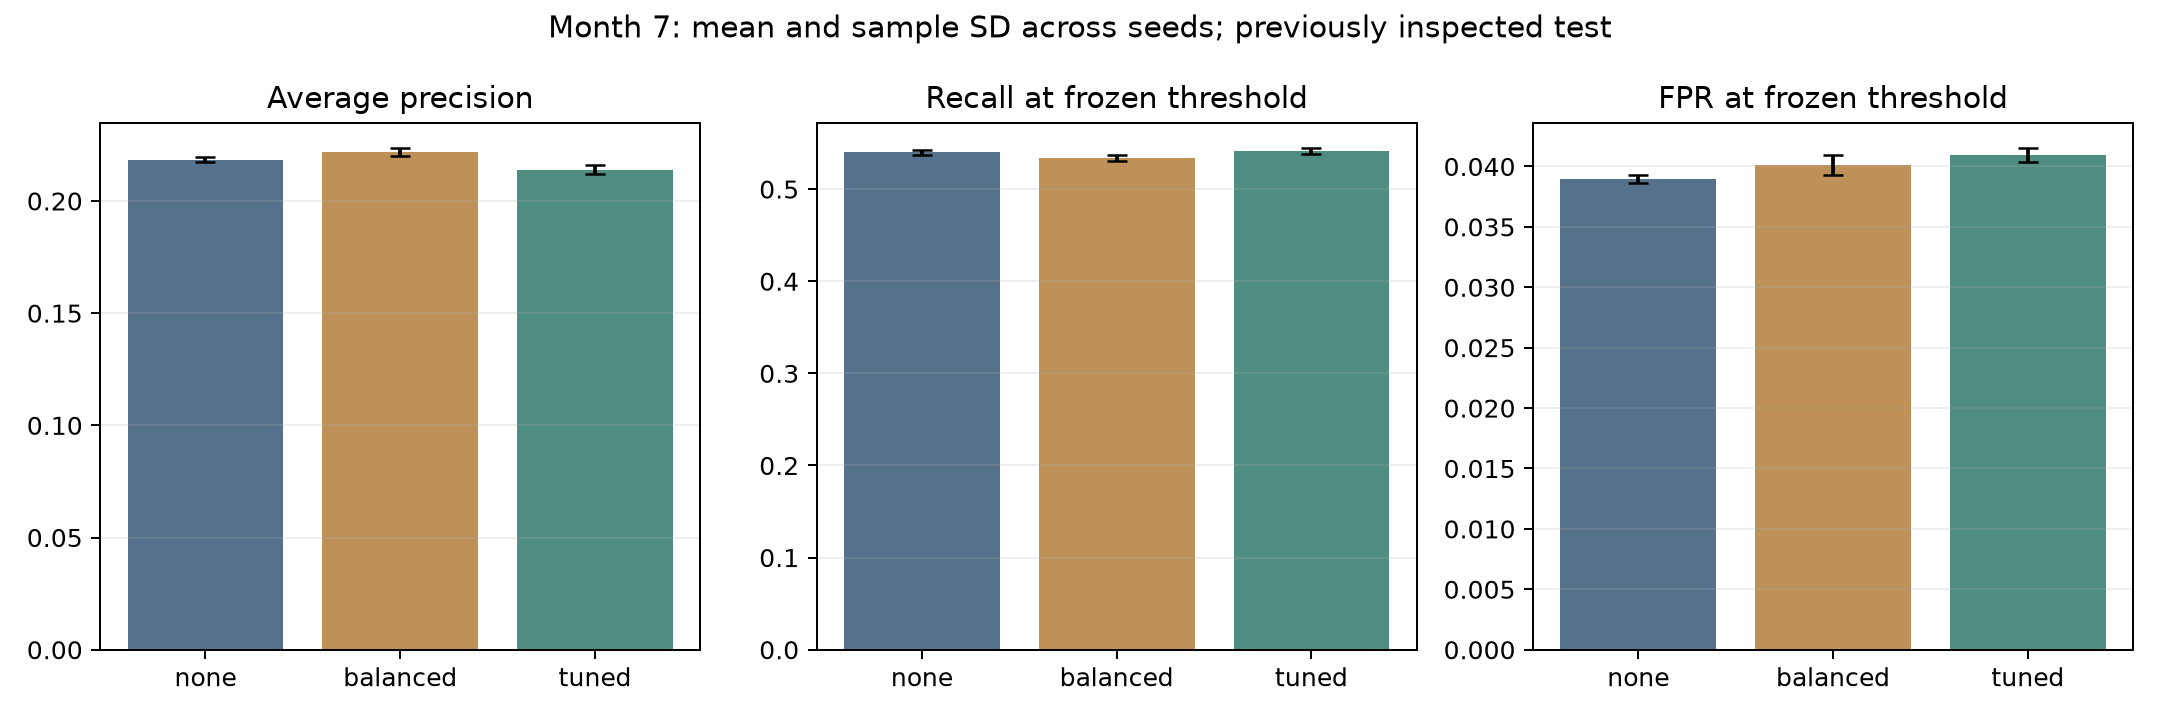

In [9]:
selections = pd.read_csv(RUN_DIR / "selections.csv")
summary = pd.read_csv(RUN_DIR / "summary.csv")
deltas = pd.read_csv(RUN_DIR / "deltas.csv")

print("Selected using validation only:")
display(selections)
print("Test: mean and sample standard deviation across seeds:")
display(summary[summary.partition == "test"])
print("Paired test deltas vs none; recall/FPR deltas use percentage points:")
display(deltas)
display(Image(filename=str(RUN_DIR / "test_comparison.png")))


**Diễn giải:** AP là chỉ số chính đã chốt trước. Recall/precision/FPR dùng
ngưỡng cố định từ validation. FPR test có thể vượt 5% do thay đổi phân phối;
không gọi recall này là recall tại đúng FPR5% trên test.

Nếu `tuned` chọn power0 thì validation chọn không tái trọng số cho cấu hình đó.
Nếu không cải thiện AP trên test, ghi nhận kết quả đó; không chọn lại power,
seed hoặc candidate theo test. Sample std của 3 seed không phải khoảng tin cậy.
Cách tuning trọng số này là một mở rộng thực nghiệm, không tự nhận là thuật toán mới.